In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [57]:
df=pd.read_csv(r"ai_resume_screening.csv")

In [58]:
df.head()

,years_experience,skills_match_score,education_level,project_count,resume_length,github_activity,shortlisted
0,6,84.7,Bachelors,7,234,158,No
1,3,59.1,Masters,5,502,77,No
2,12,100.0,Masters,12,753,381,Yes
3,14,66.8,High School,8,529,407,Yes
4,10,99.6,Bachelors,10,754,331,Yes


In [59]:
df.tail()

,years_experience,skills_match_score,education_level,project_count,resume_length,github_activity,shortlisted
29995,9,77.4,Bachelors,13,691,434,Yes
29996,5,77.8,Bachelors,9,473,149,No
29997,1,64.6,Bachelors,7,247,82,No
29998,7,94.8,Bachelors,12,584,409,Yes
29999,14,77.3,Masters,25,694,790,Yes


In [60]:
df.shape

(30000, 7)

In [61]:
df.columns

Index(['years_experience', 'skills_match_score', 'education_level',
       'project_count', 'resume_length', 'github_activity', 'shortlisted'],
      dtype='str')

In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   years_experience    30000 non-null  int64  
 1   skills_match_score  30000 non-null  float64
 2   education_level     30000 non-null  str    
 3   project_count       30000 non-null  int64  
 4   resume_length       30000 non-null  int64  
 5   github_activity     30000 non-null  int64  
 6   shortlisted         30000 non-null  str    
dtypes: float64(1), int64(4), str(2)
memory usage: 1.9 MB


In [63]:
df.describe

<bound method NDFrame.describe of        years_experience  skills_match_score education_level  project_count  \
0                     6                84.7       Bachelors              7   
1                     3                59.1         Masters              5   
2                    12               100.0         Masters             12   
3                    14                66.8     High School              8   
4                    10                99.6       Bachelors             10   
...                 ...                 ...             ...            ...   
29995                 9                77.4       Bachelors             13   
29996                 5                77.8       Bachelors              9   
29997                 1                64.6       Bachelors              7   
29998                 7                94.8       Bachelors             12   
29999                14                77.3         Masters             25   

       resume_length  github_

In [64]:
df.dtypes

years_experience        int64
skills_match_score    float64
education_level           str
project_count           int64
resume_length           int64
github_activity         int64
shortlisted               str
dtype: object

In [65]:
df.isnull().sum()

years_experience      0
skills_match_score    0
education_level       0
project_count         0
resume_length         0
github_activity       0
shortlisted           0
dtype: int64

In [66]:
(df.isnull().sum()/len(df))*100

years_experience      0.0
skills_match_score    0.0
education_level       0.0
project_count         0.0
resume_length         0.0
github_activity       0.0
shortlisted           0.0
dtype: float64

In [67]:
df.duplicated().sum()

np.int64(0)

In [68]:
df["shortlisted"].value_counts()

shortlisted
Yes    20966
No      9034
Name: count, dtype: int64

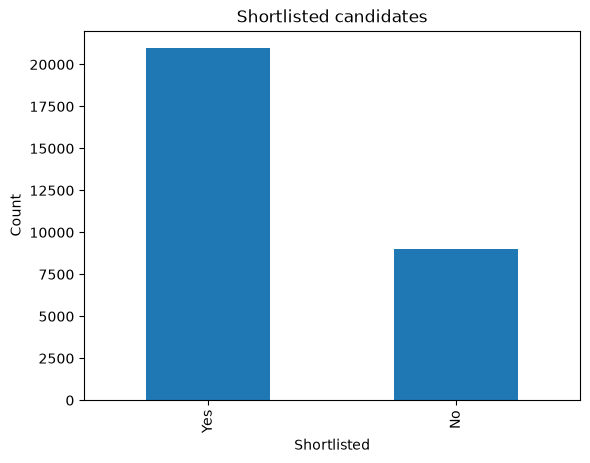

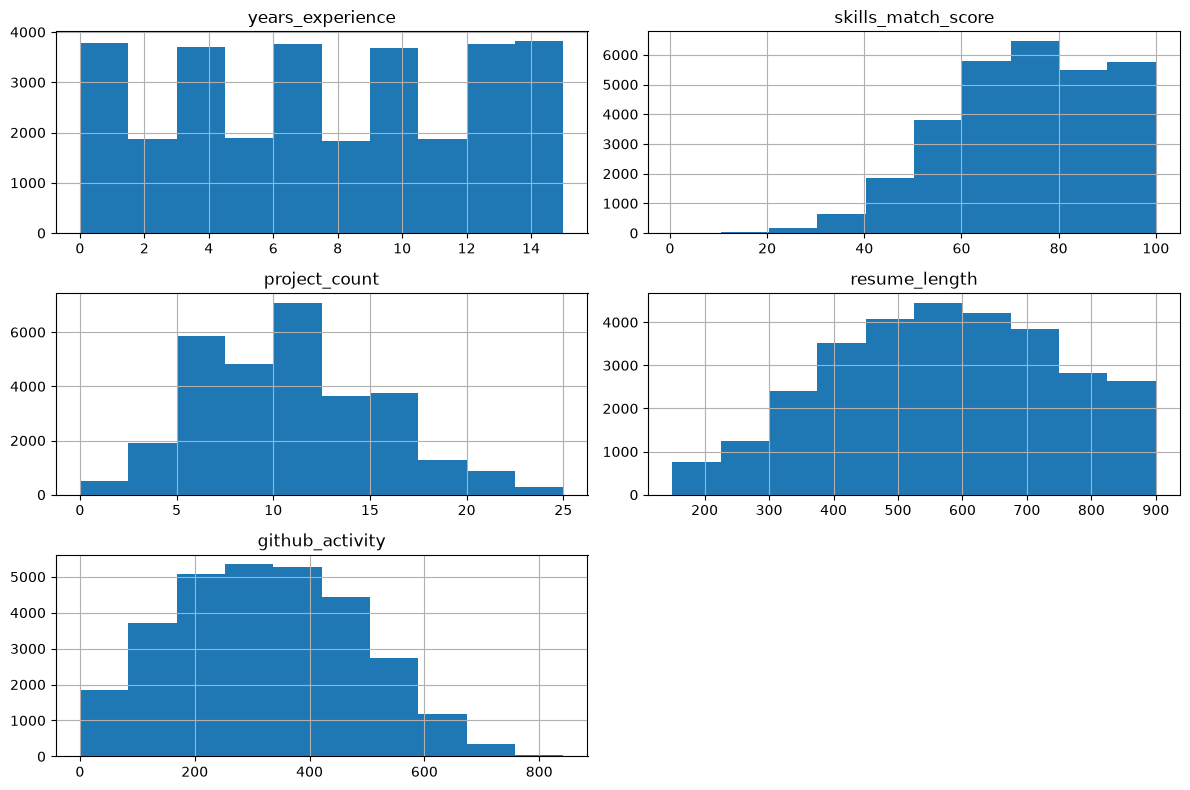

In [69]:
df["shortlisted"].value_counts().plot(kind="bar", title="Shortlisted candidates")
plt.xlabel("Shortlisted")
plt.ylabel("Count")
plt.show()

df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

In [70]:
df[df['years_experience']<0]

,years_experience,skills_match_score,education_level,project_count,resume_length,github_activity,shortlisted


In [71]:
df[df['project_count']<0]

,years_experience,skills_match_score,education_level,project_count,resume_length,github_activity,shortlisted


In [72]:
df.loc[df['years_experience']<0,'years_experience']=np.nan

In [73]:
df.loc[df['project_count']<0,'project_count']=np.nan

In [74]:
numerical_cols = df.select_dtypes(include=['int64','float64']).columns

numerical_cols

Index(['years_experience', 'skills_match_score', 'project_count',
       'resume_length', 'github_activity'],
      dtype='str')

In [75]:
df['education_level'].unique()

<ArrowStringArray>
['Bachelors', 'Masters', 'High School', 'PhD']
Length: 4, dtype: str

In [76]:
df['education_level']=df['education_level'].map({
    'Bachelors':0,
    'Masters':1,
    'High School':2,
    'PhD':3,
})

In [77]:
X = df.drop("shortlisted", axis=1)
y = df["shortlisted"].map({'No': 0, 'Yes': 1})

print("Target counts after mapping:")
print(y.value_counts(dropna=False))
print("Missing target values:", y.isna().sum())

Target counts after mapping:
shortlisted
1    20966
0     9034
Name: count, dtype: int64
Missing target values: 0


In [78]:
y

0        0
1        0
2        1
3        1
4        1
        ..
29995    1
29996    0
29997    0
29998    1
29999    1
Name: shortlisted, Length: 30000, dtype: int64

In [79]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

import joblib

In [80]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 24000
Testing rows: 6000


In [81]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained")

Logistic Regression trained


In [82]:
decision_tree_model = DecisionTreeClassifier(random_state=42)
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained")

Decision Tree trained


In [83]:
random_forest_model = RandomForestClassifier(n_estimators=100, random_state=42)
random_forest_model.fit(X_train, y_train)

print("Random Forest trained")

Random Forest trained


In [84]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

print("KNN trained")

KNN trained


In [85]:
svm_model = SVC(probability=True, random_state=42)
svm_model.fit(X_train, y_train)

print("SVM trained")

SVM trained


In [86]:
gradient_boosting_model = GradientBoostingClassifier(random_state=42)
gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting trained")

Gradient Boosting trained


In [87]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "KNN": knn_model,
    "SVM": svm_model,
    "Gradient Boosting": gradient_boosting_model
}

print("Models ready:", list(models.keys()))

Models ready: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'SVM', 'Gradient Boosting']


In [88]:
results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

results = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
display(results.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
5,Gradient Boosting,0.907,0.928,0.940,0.934
2,Random Forest,0.902,0.922,0.939,0.931
0,Logistic Regression,0.899,0.923,0.933,0.928
4,SVM,0.880,0.908,0.922,0.915
3,KNN,0.866,0.900,0.910,0.905
1,Decision Tree,0.862,0.901,0.901,0.901


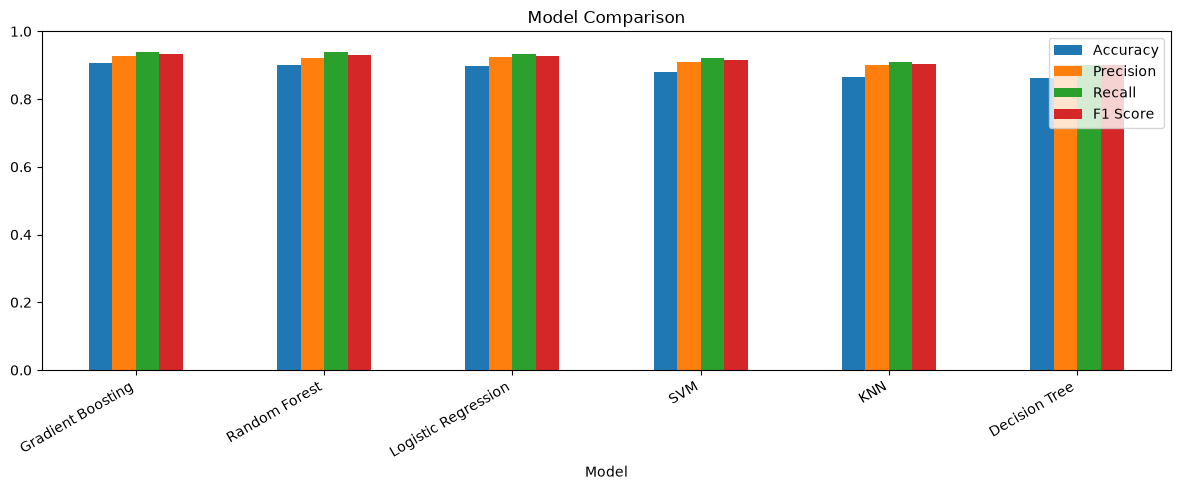

In [89]:
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1), title="Model Comparison"
)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.legend(loc='upper right')
plt.show()

Selected by test F1-score: Gradient Boosting


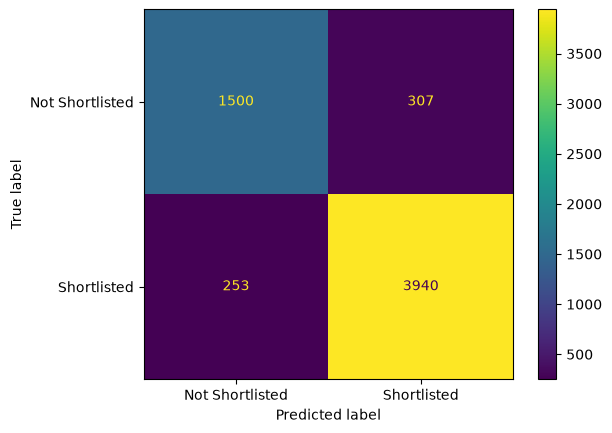

In [90]:
best_name = results.iloc[0]["Model"]
best_model = models[best_name]
predictions = best_model.predict(X_test)

print("Selected by test F1-score:", best_name)
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=["Not Shortlisted", "Shortlisted"]
)
plt.show()

In [94]:
new_candidate = pd.DataFrame([{
    "years_experience": 0,
    "skills_match_score": 100.0,
    "project_count": 19,
    "resume_length": 30,
    "github_activity": 100,
    "education_level": "Bachelors"
}])


education_mapping = {
    "Bachelors": 0,
    "Masters": 1,
    "High School": 2,
    "PhD": 3
}
new_candidate["education_level"] = new_candidate["education_level"].map(education_mapping)
new_candidate = new_candidate.reindex(columns=X.columns, fill_value=0)

answer = best_model.predict(new_candidate)[0]
probability = best_model.predict_proba(new_candidate)[0, 1]

print("Prediction:", "Shortlisted" if answer == 1 else "Not Shortlisted")
print(f"Estimated shortlist probability: {probability:.2%}")

Prediction: Not Shortlisted
Estimated shortlist probability: 21.75%


In [ ]:

joblib.dump(best_model, "resume_screening_model.joblib")
joblib.dump(X.columns.tolist(), "resume_feature_columns.joblib")

print("Model and feature columns saved successfully")

Model and feature columns saved successfully


In [93]:
loaded_model = joblib.load("resume_screening_model.joblib")
loaded_columns = joblib.load("resume_feature_columns.joblib")

new_candidate = new_candidate.reindex(columns=loaded_columns, fill_value=0)
answer = loaded_model.predict(new_candidate)[0]
probability = loaded_model.predict_proba(new_candidate)[0, 1]

print("Loaded model prediction:", "Shortlisted" if answer == 1 else "Not Shortlisted")
print(f"Estimated shortlist probability: {probability:.2%}")

Loaded model prediction: Shortlisted
Estimated shortlist probability: 79.61%
